<a href="https://colab.research.google.com/github/Irene-sketch/AI_ML_sem5/blob/main/CLUSTERING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Confusion Matrix:
[[50  0  0]
 [ 0 48  2]
 [ 0 14 36]]

Accuracy:
89.33 %

Adjusted Rand Index:
0.73

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        50
  versicolor       0.77      0.96      0.86        50
   virginica       0.95      0.72      0.82        50

    accuracy                           0.89       150
   macro avg       0.91      0.89      0.89       150
weighted avg       0.91      0.89      0.89       150


Cluster Centers (Measurements - Sepal Length, Sepal Width, Petal Length, Petal Width):
[[6.85       3.07368421 5.74210526 2.07105263]
 [5.006      3.428      1.462      0.246     ]
 [5.9016129  2.7483871  4.39354839 1.43387097]]


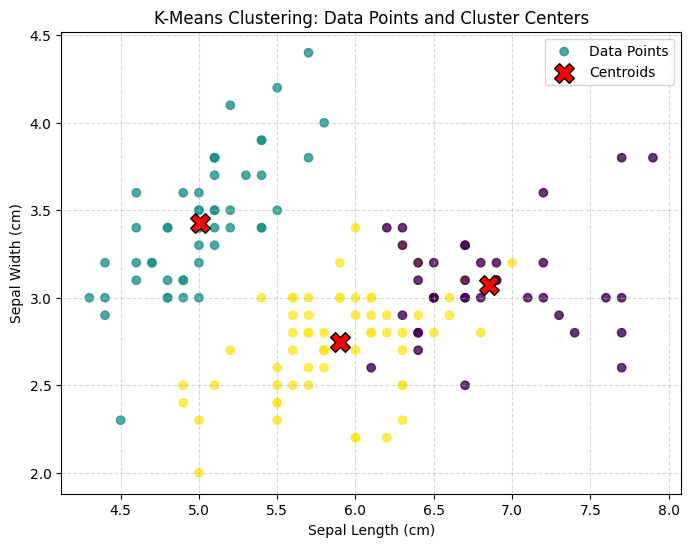

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import adjusted_rand_score
from scipy.optimize import linear_sum_assignment
import numpy as np

# 1. Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# 2. Run K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=10, n_init=10)
labels = kmeans.fit_predict(X)

# 3. Match clusters with actual classes for evaluation
cm = confusion_matrix(y, labels)
row_ind, col_ind = linear_sum_assignment(-cm)
matched_labels = np.zeros_like(labels)
for cluster, class_id in zip(col_ind, row_ind):
    matched_labels[labels == cluster] = class_id

# 4. Display numerical results and measurements
print("Confusion Matrix:")
print(confusion_matrix(y, matched_labels))

print("\nAccuracy:")
print(round(accuracy_score(y, matched_labels) * 100, 2), "%")

print("\nAdjusted Rand Index:")
print(round(adjusted_rand_score(y, labels), 3))

print("\nClassification Report:")
print(classification_report(y, matched_labels, target_names=iris.target_names))

print("\nCluster Centers (Measurements - Sepal Length, Sepal Width, Petal Length, Petal Width):")
print(kmeans.cluster_centers_)

# 5. Plot data points and cluster centers together (using first two dimensions)
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', label='Data Points', alpha=0.8)

centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=200, label='Centroids', edgecolor='black')

plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.title('K-Means Clustering: Data Points and Cluster Centers')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()